In [1]:
import sys; sys.path.append("..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from src.features import add_features

train = add_features(pd.read_csv("../data/processed/train.csv"))
print(train.shape)   # attendu : 59 004 lignes pour être sûre de ne pas avoir ouvert le test

(59004, 20)


count      59004.0
mean      136700.0
std       116185.0
min         5000.0
1%         15000.0
5%         28000.0
25%        60000.0
50%       109000.0
75%       168000.0
95%       350000.0
99%       625000.0
max      1000000.0
Name: Price, dtype: float64
Skew prix : 2.57 | Skew log : -0.13


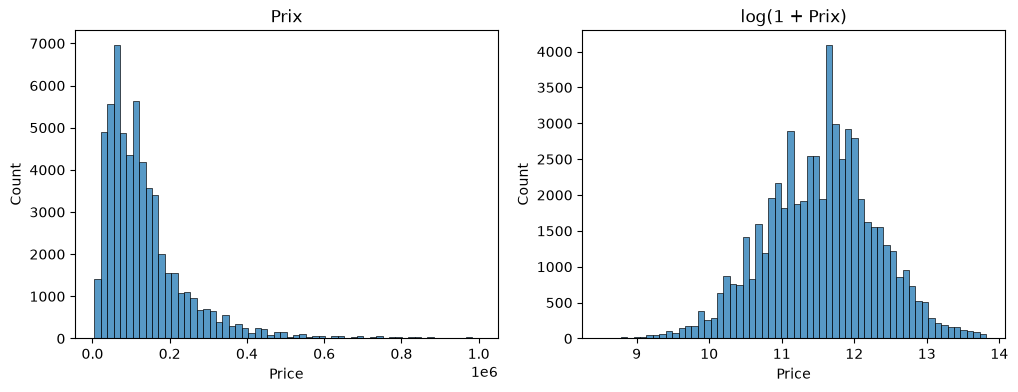

In [2]:
p = train["Price"]
print(p.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(0))
print("Skew prix :", round(p.skew(), 2), "| Skew log :", round(np.log1p(p).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(p, bins=60, ax=ax[0]);           ax[0].set_title("Prix")
sns.histplot(np.log1p(p), bins=60, ax=ax[1]); ax[1].set_title("log(1 + Prix)")
plt.show()

In [3]:
g = (train.groupby("Brand")["Price"]
          .agg(["count", "median"])
          .sort_values("count", ascending=False))
print(g.head(15))

               count    median
Brand                         
Renault         7319   84000.0
Volkswagen      7069  138000.0
Peugeot         5483   70000.0
Dacia           4950  110000.0
Mercedes-Benz   4153  130000.0
Fiat            3688   58000.0
Hyundai         3184  125000.0
Ford            3048  115000.0
Citroen         2555   85000.0
Audi            1839  225000.0
BMW             1650  210000.0
Toyota          1627   98000.0
Kia             1600   74000.0
Opel            1367  125000.0
Land Rover      1225  280000.0


In [4]:
cols = ["Price", "mileage_num", "car_age", "fiscal_power_num", "Number of Doors"]
print(train[cols].corr(method="spearman")["Price"].round(2))

Price               1.00
mileage_num        -0.23
car_age            -0.79
fiscal_power_num    0.17
Number of Doors     0.07
Name: Price, dtype: float64


In [5]:
print(train["Mileage"].value_counts(dropna=False).head(15))
print("Part de NaN :", train["mileage_num"].isna().mean().round(3))
print(train[["mileage_num", "car_age", "Price"]].corr(method="spearman").round(2))

Mileage
200 000 - 249 999    6523
250 000 - 299 999    3340
190 000 - 199 999    2893
100 000 - 109 999    2616
0 - 4 999            2549
150 000 - 159 999    2352
120 000 - 129 999    2269
140 000 - 149 999    2207
130 000 - 139 999    2138
180 000 - 189 999    2123
170 000 - 179 999    2078
160 000 - 169 999    2057
300 000 - 349 999    1998
110 000 - 119 999    1871
20 000 - 24 999      1697
Name: count, dtype: int64
Part de NaN : 0.037
             mileage_num  car_age  Price
mileage_num         1.00     0.39  -0.23
car_age             0.39     1.00  -0.79
Price              -0.23    -0.79   1.00


         count    median
car_age                 
0.0        470  230000.0
1.0       1115  225000.0
2.0       2258  195000.0
3.0       3095  185000.0
4.0       2610  175000.0
5.0       4165  165000.0
6.0       4129  160000.0
7.0       3292  155000.0
8.0       3173  150000.0
9.0       2560  140000.0
10.0      2441  130000.0
11.0      2235  115000.0
12.0      2690  100000.0
13.0      2282   90000.0
14.0      2257   82000.0
15.0      2229   73000.0
16.0      2425   68000.0
17.0      2060   62000.0
18.0      1565   58000.0
19.0      1358   55000.0
20.0      1023   55000.0
21.0      1012   50000.0
22.0       916   48000.0
23.0       884   44000.0
24.0       856   41500.0
25.0       702   36000.0
26.0       632   35000.0
27.0       461   30000.0
28.0       411   33000.0
29.0       417   40000.0
30.0       435   37000.0
31.0       366   36000.0
32.0       391   33000.0
33.0       343   32000.0
34.0       288   32000.0
35.0       262   29000.0
36.0       198   30000.0
37.0       236   28000.0


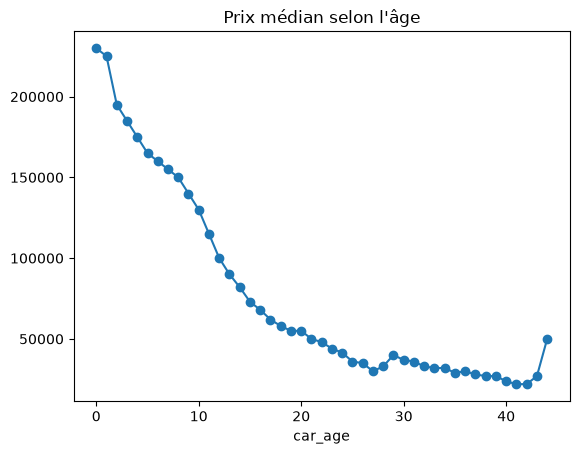

In [6]:
by_age = train.groupby("car_age")["Price"].agg(["count", "median"])
ok = by_age.query("count >= 30")
print(ok)
ok["median"].plot(marker="o", title="Prix médian selon l'âge")
plt.show()

In [7]:
low = train[train["Mileage"] == "0 - 4 999"]
print(low["car_age"].describe())
print(low["car_age"].value_counts().sort_index().head(15))

count    2549.000000
mean       16.648882
std        11.249084
min         0.000000
25%         7.000000
50%        16.000000
75%        25.000000
max        44.000000
Name: car_age, dtype: float64
car_age
0.0     210
1.0      99
2.0      78
3.0      62
4.0      41
5.0      59
6.0      52
7.0      59
8.0      58
9.0      51
10.0     41
11.0     45
12.0     75
13.0     64
14.0     79
Name: count, dtype: int64


In [8]:
print("Lignes suspectes :", train["mileage_suspect"].sum())
print(train[["mileage_num", "car_age", "Price"]].corr(method="spearman").round(2))

Lignes suspectes : 2162
             mileage_num  car_age  Price
mileage_num         1.00     0.39  -0.23
car_age             0.39     1.00  -0.79
Price              -0.23    -0.79   1.00


In [9]:
sub = train[(train["car_age"] == 8) & (train["mileage_suspect"] == 0)]
t = sub.groupby("Mileage")["Price"].agg(["count", "median"])
t = t[t["count"] >= 30].sort_values("median", ascending=False)
print(t)

                   count    median
Mileage                           
300 000 - 349 999     38  168000.0
80 000 - 84 999       62  162500.0
180 000 - 189 999    179  162000.0
170 000 - 179 999    204  158999.5
190 000 - 199 999    182  158500.0
200 000 - 249 999    264  158000.0
120 000 - 129 999    246  157500.0
150 000 - 159 999    261  156000.0
140 000 - 149 999    256  155000.0
160 000 - 169 999    224  150000.0
130 000 - 139 999    205  150000.0
100 000 - 109 999    180  150000.0
250 000 - 299 999     69  148998.0
110 000 - 119 999    192  146500.0
10 000 - 14 999       59  140000.0
85 000 - 89 999       37  140000.0
95 000 - 99 999       66  128000.0
15 000 - 19 999       62  127000.0
90 000 - 94 999       61  125000.0
70 000 - 74 999       37  110000.0
20 000 - 24 999       34  102100.0


In [10]:
sub = train[(train["car_age"] == 8) & (train["mileage_suspect"] == 0)]

# 1) même tableau, trié par kilométrage
t = (sub.groupby("Mileage")
        .agg(count=("Price", "size"), median=("Price", "median"), km=("mileage_num", "first"))
        .query("count >= 30").sort_values("km"))
print(t)

# 2) le carburant explique-t-il l'effet ?
print(sub.groupby("Fuel")["Price"].agg(["count", "median"]))
print(sub.groupby("Fuel")["mileage_num"].median())

# 3) corrélation kilométrage/prix dans chaque âge
for a in range(3, 16):
    s = train[(train["car_age"] == a) & (train["mileage_suspect"] == 0)]
    print(a, round(s["mileage_num"].corr(s["Price"], method="spearman"), 2))

                   count    median        km
Mileage                                     
10 000 - 14 999       59  140000.0   12499.5
15 000 - 19 999       62  127000.0   17499.5
20 000 - 24 999       34  102100.0   22499.5
70 000 - 74 999       37  110000.0   72499.5
80 000 - 84 999       62  162500.0   82499.5
85 000 - 89 999       37  140000.0   87499.5
90 000 - 94 999       61  125000.0   92499.5
95 000 - 99 999       66  128000.0   97499.5
100 000 - 109 999    180  150000.0  104999.5
110 000 - 119 999    192  146500.0  114999.5
120 000 - 129 999    246  157500.0  124999.5
130 000 - 139 999    205  150000.0  134999.5
140 000 - 149 999    256  155000.0  144999.5
150 000 - 159 999    261  156000.0  154999.5
160 000 - 169 999    224  150000.0  164999.5
170 000 - 179 999    204  158999.5  174999.5
180 000 - 189 999    179  162000.0  184999.5
190 000 - 199 999    182  158500.0  194999.5
200 000 - 249 999    264  158000.0  224999.5
250 000 - 299 999     69  148998.0  274999.5
300 000 - 

In [11]:
sub = train[(train["car_age"] == 8) & (train["mileage_suspect"] == 0)]

# 1) corrélation km/prix pour chaque âge, affichée de façon compacte
res = {}
for a in range(3, 16):
    s = train[(train["car_age"] == a) & (train["mileage_suspect"] == 0)]
    res[a] = round(s["mileage_num"].corr(s["Price"], method="spearman"), 2)
print(pd.Series(res))

# 2) carburant à l'âge 8 : effectif, prix médian, kilométrage médian
print(sub.groupby("Fuel").agg(count=("Price", "size"),
                              prix_median=("Price", "median"),
                              km_median=("mileage_num", "median")))

# 3) corrélation km/prix à l'intérieur de chaque carburant (âge 8)
for f, g in sub.groupby("Fuel"):
    if len(g) >= 100:
        print(f, len(g), round(g["mileage_num"].corr(g["Price"], method="spearman"), 2))

3    -0.04
4     0.08
5     0.03
6     0.02
7     0.12
8     0.10
9     0.09
10    0.08
11    0.18
12    0.20
13    0.23
14    0.23
15    0.24
dtype: float64
            count  prix_median  km_median
Fuel                                     
Diesel       2875     155000.0   144999.5
Electrique      3     115000.0   164999.5
Hybrid          8     270000.0   174999.5
Petrol        229      93000.0   104999.5
Diesel 2875 0.06
Petrol 229 -0.13


In [12]:
for c in ["Fuel", "Gearbox", "Condition", "Origin", "First Owner"]:
    print(train.groupby(c, dropna=False)["Price"].agg(["count", "median"]).sort_values("count", ascending=False).head(8))
    print()
print(train[["Model", "Location", "Sector"]].nunique())

            count    median
Fuel                       
Diesel      46952  120000.0
Petrol      11362   55000.0
Hybrid        489  250000.0
Electrique    157  223600.0
LPG            44   88500.0

           count    median
Gearbox                   
Manual     41555   82000.0
Automatic  17449  210000.0

           count    median
Condition                 
Excellent  24919  140000.0
Very Good  20962   96000.0
Good        8042   55000.0
New         2012  160000.0
NaN         1726   79000.0
Fair        1251   37000.0
Damaged       54   31000.0
For Parts     38   28500.0

                             count    median
Origin                                      
WW in Morocco                38648  117000.0
Customs-cleared car          10705   78000.0
NaN                           6620   76000.0
Imported New                  2605  155000.0
Car not yet customs-cleared    426  134000.0

             count    median
First Owner                 
No           33480   85000.0
Yes          18230  

In [13]:
for c in ["Origin", "First Owner"]:
    print(train.groupby(c, dropna=False)["Price"].agg(["count", "median"])
               .sort_values("count", ascending=False).head(8))
    print()

for c in ["Model", "Location", "Sector"]:
    vc = train[c].value_counts()
    rares = vc[vc < 30]
    print(c, "| distincts :", len(vc),
          "| valeurs < 30 annonces :", len(rares),
          "| part des lignes concernées :", round(rares.sum() / len(train), 3),
          "| top 50 couvrent :", round(vc.head(50).sum() / len(train), 3))

                             count    median
Origin                                      
WW in Morocco                38648  117000.0
Customs-cleared car          10705   78000.0
NaN                           6620   76000.0
Imported New                  2605  155000.0
Car not yet customs-cleared    426  134000.0

             count    median
First Owner                 
No           33480   85000.0
Yes          18230  155000.0
NaN           7294   95000.0

Model | distincts : 916 | valeurs < 30 annonces : 632 | part des lignes concernées : 0.075 | top 50 couvrent : 0.521
Location | distincts : 360 | valeurs < 30 annonces : 270 | part des lignes concernées : 0.022 | top 50 couvrent : 0.937
Sector | distincts : 805 | valeurs < 30 annonces : 552 | part des lignes concernées : 0.079 | top 50 couvrent : 0.664


In [14]:
for c in ["Model", "Location", "Sector"]:
    vc = train[c].value_counts()
    rares = vc[vc < 30]
    print(c)
    print("  part des lignes dans valeurs rares :", round(rares.sum() / len(train), 3))
    print("  part couverte par les 50 plus fréquentes :", round(vc.head(50).sum() / len(train), 3))

Model
  part des lignes dans valeurs rares : 0.075
  part couverte par les 50 plus fréquentes : 0.521
Location
  part des lignes dans valeurs rares : 0.022
  part couverte par les 50 plus fréquentes : 0.937
Sector
  part des lignes dans valeurs rares : 0.079
  part couverte par les 50 plus fréquentes : 0.664


In [15]:
print(train["Equipment"].isna().mean().round(3))
print(train["Equipment"].dropna().sample(8, random_state=42).tolist())
print(train["Equipment"].nunique())

0.0
["['Electric Windows', 'CD/MP3/Bluetooth']", "['CD/MP3/Bluetooth', 'CD/MP3/Bluetooth']", "['ABS', 'Airbags', 'CD/MP3/Bluetooth', 'Rear Camera', 'Air Conditioning', 'Alloy Wheels', 'Speed Limiter', 'Onboard Computer', 'Parking Sensors', 'Cruise Control', 'Leather Seats', 'Navigation System/GPS', 'Sunroof', 'Central Locking', 'Electric Windows']", "['Electric Windows', 'Rear Camera']", "['ABS', 'CD/MP3/Bluetooth', 'Air Conditioning', 'ESP', 'Alloy Wheels', 'Speed Limiter', 'Onboard Computer', 'Cruise Control', 'Leather Seats', 'Central Locking', 'Electric Windows']", "['Electric Windows', 'Electric Windows']", "['CD/MP3/Bluetooth', 'Alloy Wheels']", "['ABS', 'Airbags', 'CD/MP3/Bluetooth', 'Rear Camera', 'Air Conditioning', 'ESP', 'Alloy Wheels', 'Speed Limiter', 'Onboard Computer', 'Cruise Control', 'Leather Seats', 'Navigation System/GPS', 'Central Locking', 'Electric Windows']"]
8208


In [16]:
import ast
from collections import Counter

def parse_equipment(s):
    """"['ABS', 'ESP']" -> ['ABS', 'ESP'] sans doublons ; NaN si manquant ou illisible."""
    if pd.isna(s):
        return np.nan
    try:
        items = ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return np.nan
    return sorted(set(items))

eq = train["Equipment"].map(parse_equipment)

print("NaN dans Equipment :", train["Equipment"].isna().mean().round(3))
print("Textes non lisibles :", (eq.isna() & train["Equipment"].notna()).sum())

cnt = Counter(i for L in eq.dropna() for i in L)
vocab = pd.Series(cnt).sort_values(ascending=False)
print("Équipements distincts :", len(vocab))
print((vocab / eq.notna().sum()).round(3).head(40))

n = eq.map(lambda L: len(L) if isinstance(L, list) else np.nan)
print(n.describe().round(1))
print("Spearman n_equipment/prix :", round(n.corr(train["Price"], method="spearman"), 2))
print("Spearman n_equipment/âge  :", round(n.corr(train["car_age"], method="spearman"), 2))

NaN dans Equipment : 0.0
Textes non lisibles : 0
Équipements distincts : 16
Electric Windows         0.606
CD/MP3/Bluetooth         0.561
Alloy Wheels             0.533
Air Conditioning         0.472
Airbags                  0.438
Central Locking          0.438
Rear Camera              0.397
ABS                      0.395
Leather Seats            0.339
Speed Limiter            0.339
Cruise Control           0.337
Parking Sensors          0.324
Onboard Computer         0.311
ESP                      0.298
Navigation System/GPS    0.262
Sunroof                  0.113
dtype: float64
count    59004.0
mean         6.2
std          4.9
min          1.0
25%          2.0
50%          4.0
75%         11.0
max         15.0
Name: Equipment, dtype: float64
Spearman n_equipment/prix : 0.42
Spearman n_equipment/âge  : -0.33


In [17]:
top = train["Brand"].value_counts().head(10).index
for a in [3, 8, 12]:
    s = train[(train["car_age"] == a) & (train["Brand"].isin(top))]
    print("Âge", a)
    print(s.groupby("Brand")["Price"].agg(["count", "median"])
            .query("count >= 30").sort_values("median"))
    print()

Âge 3
               count    median
Brand                         
Fiat             146  124500.0
Dacia            399  132000.0
Citroen          161  147000.0
Renault          438  153000.0
Peugeot          244  169000.0
Ford              98  222500.0
Hyundai          236  235000.0
Volkswagen       281  354000.0
Audi             128  424500.0
Mercedes-Benz     91  470000.0

Âge 8
               count    median
Brand                         
Fiat             134   85000.0
Dacia            281   99000.0
Citroen           86  105000.0
Peugeot          178  109000.0
Renault          274  115000.0
Ford             304  144000.0
Hyundai          163  145000.0
Volkswagen       443  173000.0
Audi             139  240000.0
Mercedes-Benz    175  300000.0

Âge 12
               count    median
Brand                         
Fiat             118   63000.0
Dacia            239   73000.0
Peugeot          201   75000.0
Renault          237   83000.0
Citroen          102   89000.0
Hyundai          2

In [18]:
print(train.groupby("Number of Doors", dropna=False)["Price"]
           .agg(["count", "median"]))

print(train.groupby("Number of Doors", dropna=False)["car_age"].median())

# à âge et marque comparables : les 3 portes sont-elles vraiment moins chères ?
top = train["Brand"].value_counts().head(5).index
s = train[(train["car_age"].between(5, 10)) & (train["Brand"].isin(top))]
print(s.groupby(["Brand", "Number of Doors"], dropna=False)["Price"]
        .agg(["count", "median"]).query("count >= 30"))

                 count    median
Number of Doors                 
3.0               3330   89000.0
5.0              49945  110000.0
NaN               5729   90000.0
Number of Doors
3.0    12.0
5.0    10.0
NaN    12.0
Name: car_age, dtype: float64
                               count    median
Brand         Number of Doors                 
Dacia         3.0                 94   97500.0
              5.0               2020  110000.0
              NaN                294  107000.0
Mercedes-Benz 3.0                 65  410000.0
              5.0                923  295000.0
              NaN                 86  300000.0
Peugeot       3.0                 39  105000.0
              5.0               1190  120004.5
              NaN                145  115000.0
Renault       3.0                 64  110000.0
              5.0               1839  120000.0
              NaN                227  115000.0
Volkswagen    3.0                 55  200000.0
              5.0               2347  195000.0
 